# 01 — Eksplorasi Data (EDA) MovieLens 100K

**Tujuan:** mengenal dataset sebelum membangun model, yaitu berapa banyak user, film, dan rating,
bagaimana sebaran rating, dan seberapa jarang (sparse) matriks rating-nya.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import plot_style as ps
ps.setup()
pd.set_option("display.precision", 4)
from src.data import load_ratings, load_fold, N_USERS, N_ITEMS

## 1. Membaca data rating

File `u.data` berisi satu rating per baris: **user**, **item** (film), **rating** (1–5), dan **timestamp**
(waktu memberi rating, dalam detik sejak 1 Januari 1970). Inilah *user history* yang diminta tugas.

In [2]:
ratings = load_ratings()
ratings["waktu"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings.head()

,user,item,rating,timestamp,waktu
0,196,242,3,881250949,1997-12-04 15:55:49
1,186,302,3,891717742,1998-04-04 19:22:22
2,22,377,1,878887116,1997-11-07 07:18:36
3,244,51,2,880606923,1997-11-27 05:02:03
4,166,346,1,886397596,1998-02-02 05:33:16


## 2. Statistik dasar

In [3]:
per_user = ratings.groupby("user").size()
per_item = ratings.groupby("item").size()
ringkasan = pd.Series({
    "Jumlah rating": len(ratings),
    "Jumlah user": ratings["user"].nunique(),
    "Jumlah film": ratings["item"].nunique(),
    "Rata-rata rating": round(ratings["rating"].mean(), 3),
    "Rating per user (min / median / maks)": f"{per_user.min()} / {per_user.median():.0f} / {per_user.max()}",
    "Rating per film (min / median / maks)": f"{per_item.min()} / {per_item.median():.0f} / {per_item.max()}",
    "Data kosong": int(ratings.isna().sum().sum()),
    "Duplikat pasangan user-film": int(ratings.duplicated(["user", "item"]).sum()),
    "Rentang waktu": f"{ratings['waktu'].min().date()} s.d. {ratings['waktu'].max().date()}",
})
ringkasan.to_frame("Nilai")

,Nilai
Jumlah rating,100000
Jumlah user,943
Jumlah film,1682
Rata-rata rating,3.53
Rating per user (min / median / maks),20 / 65 / 737
Rating per film (min / median / maks),1 / 27 / 583
Data kosong,0
Duplikat pasangan user-film,0
Rentang waktu,1997-09-20 s.d. 1998-04-22


## 3. Kepadatan (density) matriks rating

Jika semua user merating semua film, akan ada `943 × 1.682` sel rating. Density menunjukkan berapa persen
sel yang benar-benar terisi:

$$density = \frac{\text{jumlah rating}}{\text{jumlah user} \times \text{jumlah film}}$$

In [4]:
n_rating = len(ratings)
total_sel = N_USERS * N_ITEMS
density = n_rating / total_sel
print(f"density = {n_rating:,} / ({N_USERS} x {N_ITEMS}) = {n_rating:,} / {total_sel:,} = {density:.4f} -> {density:.2%}")
print(f"sel kosong (sparsity) = {1 - density:.2%}")

density = 100,000 / (943 x 1682) = 100,000 / 1,586,126 = 0.0630 -> 6.30%
sel kosong (sparsity) = 93.70%


## 4. Sebaran nilai rating

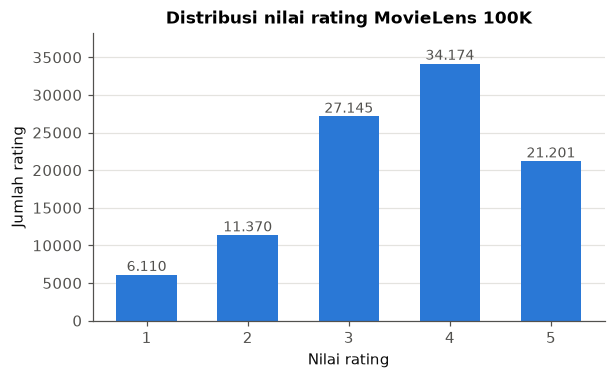

Rating >= 4 (relevan untuk NDCG): 55.38%


In [5]:
dist = ratings["rating"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(dist.index, dist.values, color=ps.BLUE, width=0.6)
for x, y in zip(dist.index, dist.values):
    ax.text(x, y + 500, f"{y:,}".replace(",", "."), ha="center", fontsize=9, color=ps.INK_2)
ax.set_xlabel("Nilai rating")
ax.set_ylabel("Jumlah rating")
ax.set_title("Distribusi nilai rating MovieLens 100K")
ax.set_ylim(0, dist.max() * 1.12)
ax.grid(axis="x", visible=False)
fig.savefig(FIG / "eda_distribusi_rating.png")
plt.show()
print(f"Rating >= 4 (relevan untuk NDCG): {(ratings['rating'] >= 4).mean():.2%}")

## 5. Banyaknya rating per user dan per film

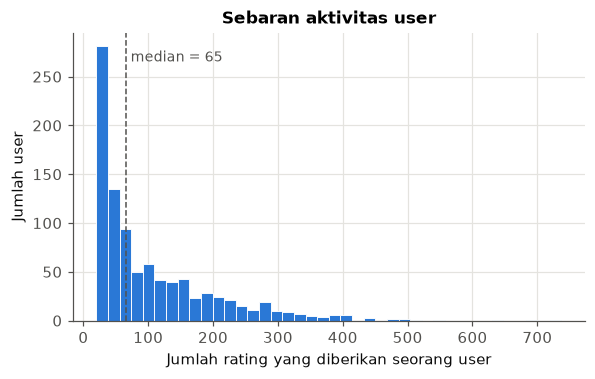

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(per_user, bins=40, color=ps.BLUE, edgecolor="white", linewidth=0.6)
ax.axvline(per_user.median(), color=ps.INK_2, linestyle="--", linewidth=1)
ax.text(per_user.median() + 8, ax.get_ylim()[1] * 0.9, f"median = {per_user.median():.0f}", color=ps.INK_2, fontsize=9)
ax.set_xlabel("Jumlah rating yang diberikan seorang user")
ax.set_ylabel("Jumlah user")
ax.set_title("Sebaran aktivitas user")
fig.savefig(FIG / "eda_rating_per_user.png")
plt.show()

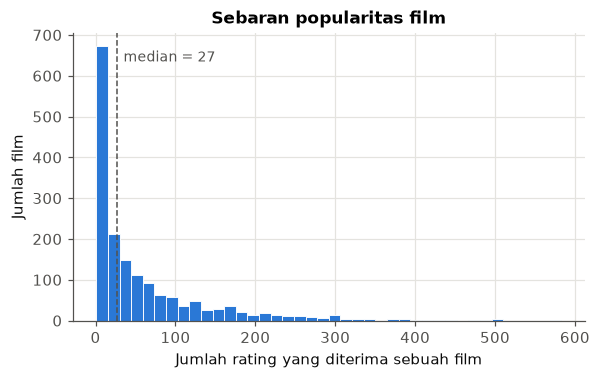

Film dengan < 5 rating: 333 dari 1682 (19.8%)


In [7]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(per_item, bins=40, color=ps.BLUE, edgecolor="white", linewidth=0.6)
ax.axvline(per_item.median(), color=ps.INK_2, linestyle="--", linewidth=1)
ax.text(per_item.median() + 8, ax.get_ylim()[1] * 0.9, f"median = {per_item.median():.0f}", color=ps.INK_2, fontsize=9)
ax.set_xlabel("Jumlah rating yang diterima sebuah film")
ax.set_ylabel("Jumlah film")
ax.set_title("Sebaran popularitas film")
fig.savefig(FIG / "eda_rating_per_film.png")
plt.show()
print(f"Film dengan < 5 rating: {(per_item < 5).sum()} dari {len(per_item)} ({(per_item < 5).mean():.1%})")

## 6. Judul film ganda

Ada beberapa film yang terdaftar dua kali dengan id berbeda (keanehan bawaan MovieLens 100K).

In [8]:
from src.data import load_items
titles = load_items()
ganda = titles[titles.duplicated(keep=False)].sort_values()
print(f"Judul ganda: {titles.duplicated().sum()} judul ({len(ganda)} id)")
print(f"Rating pada id ganda: {ratings['item'].isin(ganda.index).sum()} dari {len(ratings)} ({ratings['item'].isin(ganda.index).mean():.2%})")
ganda.head(6).to_frame()

Judul ganda: 18 judul (36 id)
Rating pada id ganda: 1269 dari 100000 (1.27%)


,title
item,
670,Body Snatchers (1993)
573,Body Snatchers (1993)
1650,"Butcher Boy, The (1998)"
1645,"Butcher Boy, The (1998)"
1234,Chairman of the Board (1998)
1654,Chairman of the Board (1998)


**Keputusan:** id ganda tetap dibiarkan terpisah saat evaluasi, karena pembagian fold resmi MovieLens
dibuat berdasarkan id dan jumlahnya hanya sekitar 1,3% rating. Saat menampilkan rekomendasi, judul yang
sama tidak boleh muncul dua kali, dan judul yang sudah pernah dirating user (melalui id kembarannya)
tidak direkomendasikan lagi.

## 7. Pembagian data latih dan uji (5-fold)

MovieLens 100K sudah menyediakan 5 pasang file `u1.base/u1.test` … `u5.base/u5.test`. Setiap fold memakai
80% rating untuk melatih model dan 20% sisanya disembunyikan untuk diuji, dan kelima test set tidak saling
beririsan. Cara ini sama dengan *5-fold cross validation* di slide Evaluasi Part 1.

In [9]:
rows = []
for k in range(1, 6):
    tr, te = load_fold(k)
    rows.append({"Fold": k, "Train": len(tr), "Test": len(te),
                 "User di test": te["user"].nunique(), "Film di test": te["item"].nunique(),
                 "Film test yang tidak ada di train": len(set(te["item"]) - set(tr["item"]))})
pd.DataFrame(rows).set_index("Fold")

,Train,Test,User di test,Film di test,Film test yang tidak ada di train
Fold,,,,,
1,80000,20000,459,1410,32
2,80000,20000,653,1420,34
3,80000,20000,869,1423,32
4,80000,20000,923,1394,22
5,80000,20000,927,1407,32


## Kesimpulan EDA

- Data bersih: tidak ada nilai kosong maupun duplikat, jadi tidak perlu pembersihan.
- Matriks rating sangat **sparse**: hanya sekitar 6,3% sel yang terisi.
- Rating condong ke nilai 3–4, dan lebih dari separuh rating bernilai ≥ 4 (relevan).
- Ada 18 judul film yang terdaftar ganda (sekitar 1,3% rating); hanya disaring saat menampilkan rekomendasi.
- Aktivitas user dan popularitas film sangat tidak merata (*long tail*): sedikit film sangat populer,
  sedangkan banyak film hanya dirating segelintir user. Film-film jarang inilah yang paling sulit diprediksi.